In [19]:
from idlelib.autocomplete import AutoComplete

# Importing the required libraries, modules, and classes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from narwhals.selectors import categorical

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score, ConfusionMatrixDisplay
)

In [20]:
# importing the Telco Customer Churn Dataset

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [21]:
# Dataset description and analysis

print("Columns: ", df.columns,"\n")
print("Count of values in each column: ", df.count(),"\n")
print("Missing values in each column: ", df.isnull().sum(),"\n")
print("Duplicate values in each column: ", df.duplicated(),"\n")
print("Datatype of each column: ", df.dtypes,"\n")

Columns:  Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str') 

Count of values in each column:  customerID          7043
gender              7043
SeniorCitizen       7043
Partner             7043
Dependents          7043
tenure              7043
PhoneService        7043
MultipleLines       7043
InternetService     7043
OnlineSecurity      7043
OnlineBackup        7043
DeviceProtection    7043
TechSupport         7043
StreamingTV         7043
StreamingMovies     7043
Contract            7043
PaperlessBilling    7043
PaymentMethod       7043
MonthlyCharges      7043
TotalCharges        7043
Churn               7043
dtype: int64 

Missing values in each column:  custo

In [22]:
# Statistical summary of the dataset

df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


array([[<Axes: title={'center': 'SeniorCitizen'}>,
        <Axes: title={'center': 'tenure'}>],
       [<Axes: title={'center': 'MonthlyCharges'}>, <Axes: >]],
      dtype=object)

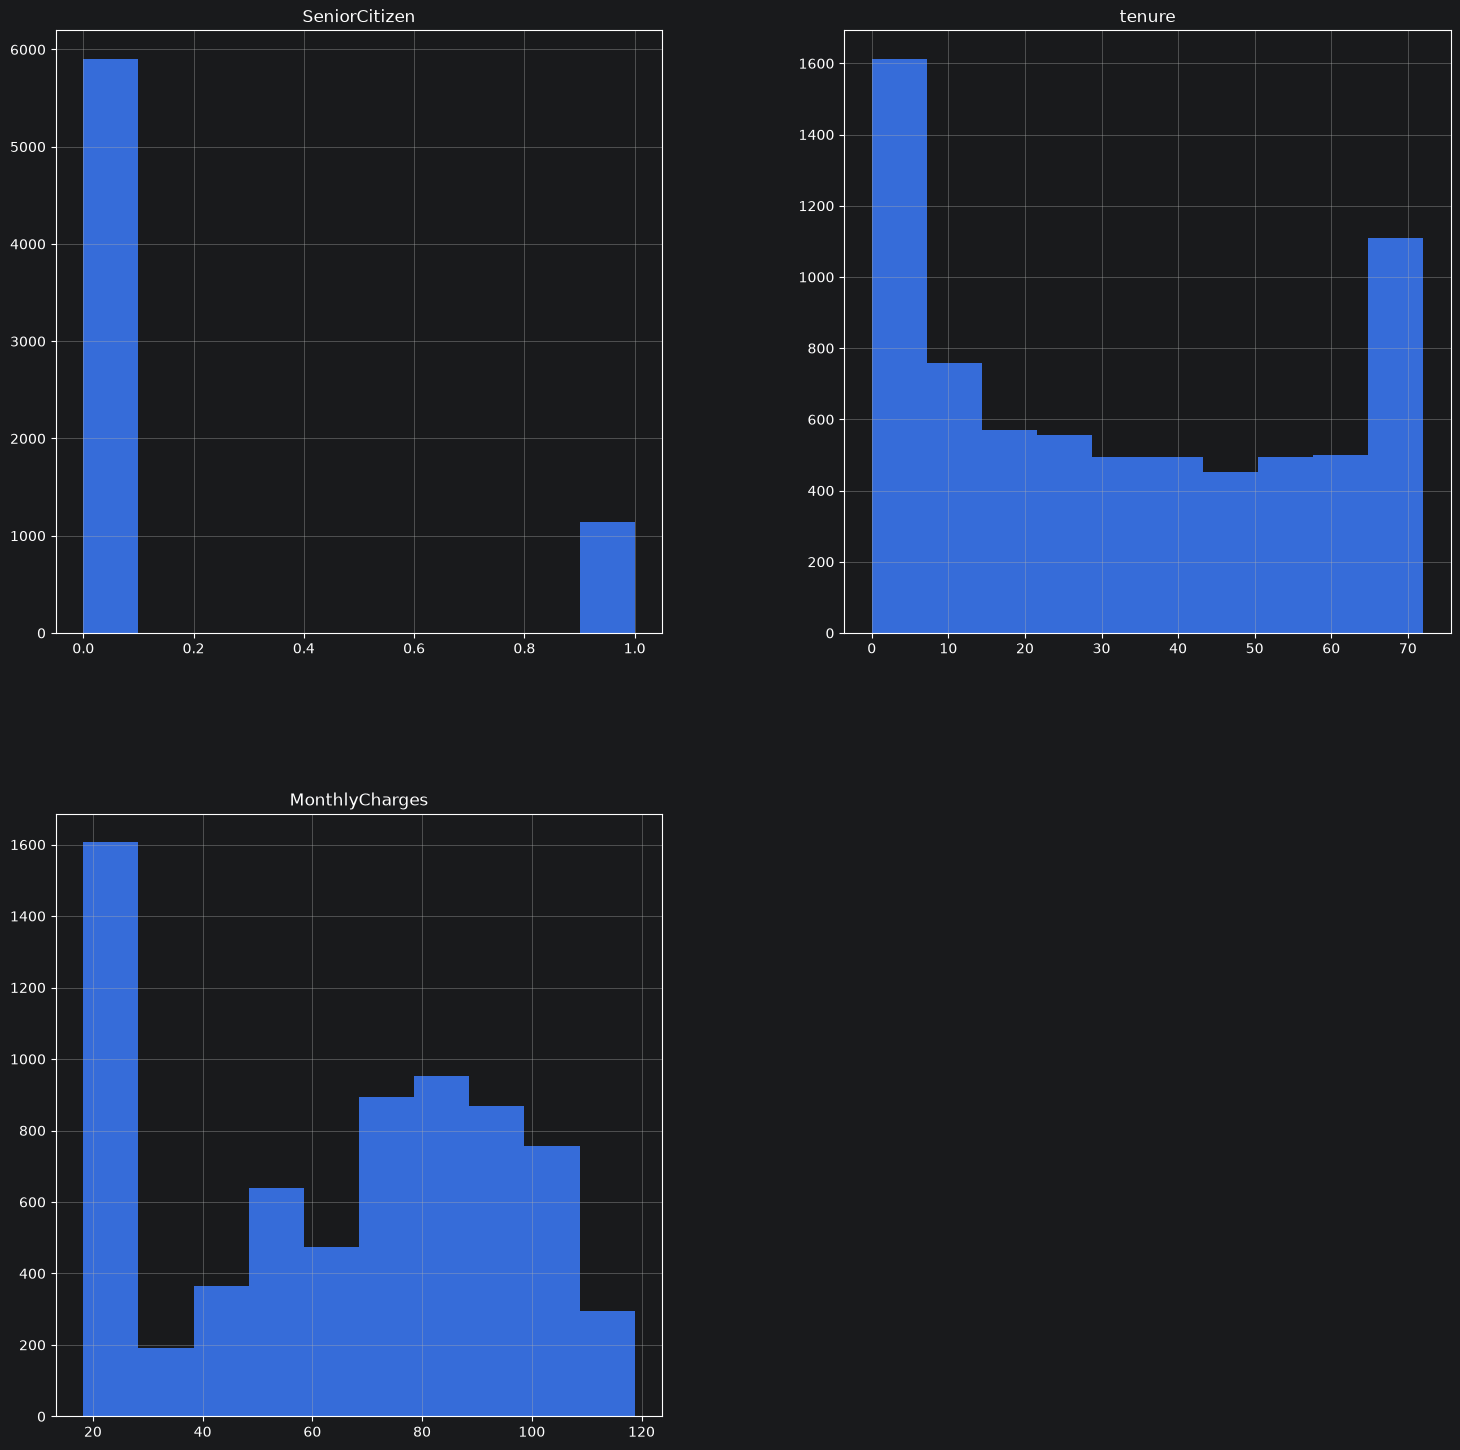

In [23]:
# Data Distribution

df.hist(figsize=(18,18))

In [24]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [25]:
# Converting TotalCharges to Float and Removing the customerID column

df = df.drop(columns=['customerID'])

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce')

In [26]:
# Separating Features and Target

X = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features Shape:", X.shape,"\n")
print("Target Shape", y.shape,"\n")

Features Shape: (7043, 19) 

Target Shape (7043,) 



In [27]:
# Identifying Numerical and Categorical columns

numerical_featuers = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
]

categorical_features = [i for i in X.columns if i not in numerical_featuers]
print("Numerical features: ", categorical_features)
print("Categorical features: ", categorical_features)

Numerical features:  ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Categorical features:  ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [28]:
# Splitting the data into training and test set

X_train,  X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Samples:", X_train.shape,"\n")
print("Testing Samples:", X_test.shape,"\n")

Training Samples: (5634, 19) 

Testing Samples: (1409, 19) 



In [29]:
# Encoding, Imputing, and Transforming the categorical columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_featuers),
        ('cat', categorical_transformer, categorical_features),
    ]
)

In [30]:
# Fit preprocessor and transform train and test sets
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Map string targets 'Yes'/'No' to binary 1/0
y_train_num = (y_train == 'Yes').astype(int)
y_test_num = (y_test == 'Yes').astype(int)

print("Preprocessed X_train shape:", X_train_trans.shape)
print("Preprocessed X_test shape:", X_test_trans.shape)

Preprocessed X_train shape: (5634, 46)
Preprocessed X_test shape: (1409, 46)


Confusion Matrix:  [[934 102]
 [150 223]]
Accuracy:  0.8211497515968772
Precision:  0.6861538461538461
Recall:  0.5978552278820375
F1:  0.6389684813753582
AUC:  0.7496998147132194
Classification Report:                precision    recall  f1-score   support

       Churn       0.86      0.90      0.88      1036
         Yes       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



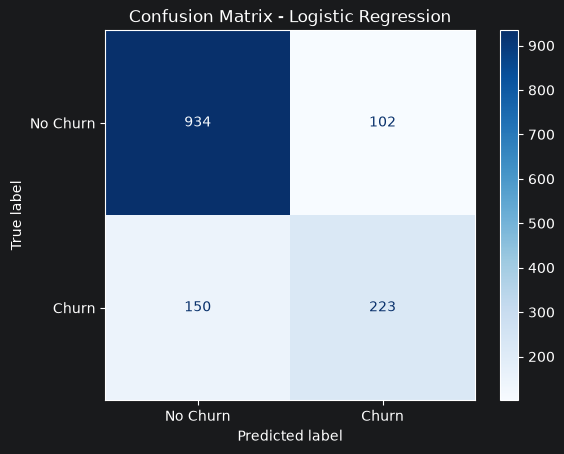

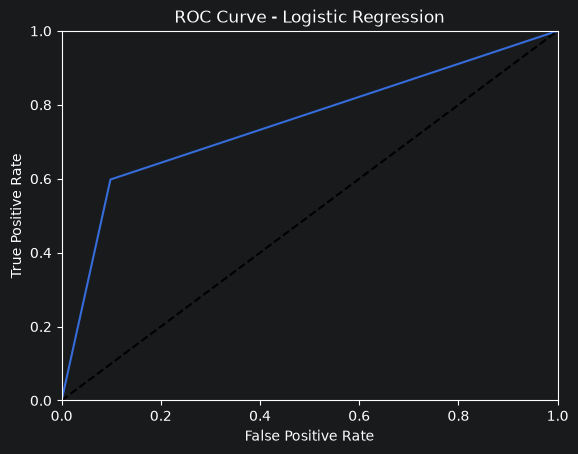

In [36]:
# Baseline Logistic Regression Model

logReg = LogisticRegression()
logReg.fit(X_train_trans, y_train_num)

logreg_pred = logReg.predict(X_test_trans)
logReg_prob = logReg.predict_proba(X_test_trans)[:,1]

logReg_confusionMatrix = confusion_matrix(y_test_num, logReg.predict(X_test_trans))
print("Confusion Matrix: ", logReg_confusionMatrix)

logReg_Accuracy = accuracy_score(y_test_num, logReg.predict(X_test_trans))
print("Accuracy: ", logReg_Accuracy)

logReg_precision = precision_score(y_test_num, logReg.predict(X_test_trans))
print("Precision: ", logReg_precision)

logReg_recall = recall_score(y_test_num, logReg.predict(X_test_trans))
print("Recall: ", logReg_recall)

logReg_F1 = f1_score(y_test_num, logReg.predict(X_test_trans))
print("F1: ", logReg_F1)

logReg_AUC = roc_auc_score(y_test_num, logReg.predict(X_test_trans))
print("AUC: ", logReg_AUC)

logReg_classificationReport = classification_report(y_test_num, logReg.predict(X_test_trans), target_names=['Churn', 'Yes'])
print("Classification Report: ", logReg_classificationReport)

ConfusionMatrixDisplay(
    confusion_matrix=logReg_confusionMatrix,
    display_labels=['No Churn', 'Churn']
).plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

fpr_logReg, tpr_logReg, thresholds_logReg = roc_curve(y_test_num, logReg.predict(X_test_trans))
plt.plot(fpr_logReg, tpr_logReg)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.show()


Decision Tree Accuracy:  0.7998580553584103
Decision Tree Precision:  0.618798955613577
Decision Tree Recall:  0.6353887399463807
Decision Tree F1 Score:  0.626984126984127
Decision Tree ROC AUC Score:  0.7472310495098698
Decision Tree Classification Report: 
               precision    recall  f1-score   support

           0       0.87      0.86      0.86      1036
           1       0.62      0.64      0.63       373

    accuracy                           0.80      1409
   macro avg       0.74      0.75      0.75      1409
weighted avg       0.80      0.80      0.80      1409

Decision Tree Confusion Matrix:
 [[890 146]
 [136 237]]


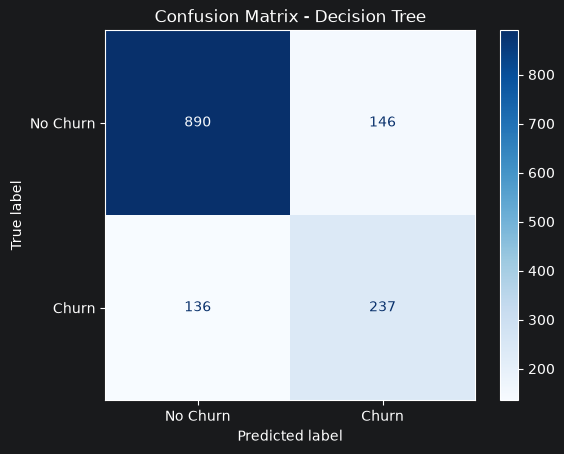

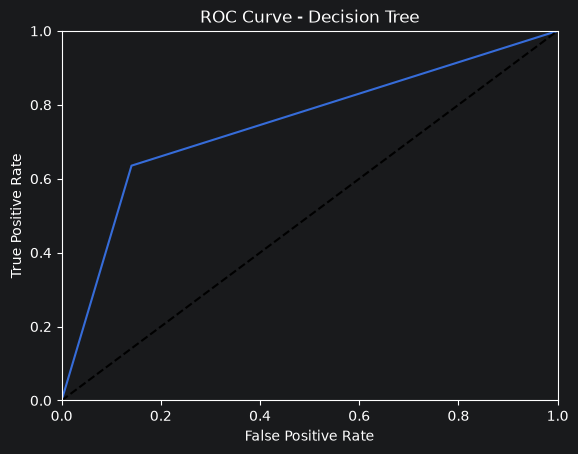

In [41]:
# Decision Tree Classifier

decTree = DecisionTreeClassifier(max_depth=5, random_state=42)
decTree.fit(X_train_trans, y_train_num)

decTree_Predictions = decTree.predict(X_test_trans)
dectree_prob = decTree.predict_proba(X_test_trans)[:,1]

decTree_Accuracy = accuracy_score(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree Accuracy: ", decTree_Accuracy)

decTree_Precision = precision_score(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree Precision: ", decTree_Precision)

decTree_Recall = recall_score(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree Recall: ", decTree_Recall)

decTree_F1 = f1_score(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree F1 Score: ", decTree_F1)

decTree_AUC = roc_auc_score(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree ROC AUC Score: ", decTree_AUC)

decTree_ClassificationReport = classification_report(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree Classification Report: \n", decTree_ClassificationReport)

decTree_Confusion = confusion_matrix(y_test_num, decTree.predict(X_test_trans))
print("Decision Tree Confusion Matrix:\n", decTree_Confusion)

ConfusionMatrixDisplay(
    confusion_matrix=decTree_Confusion,
    display_labels=['No Churn', 'Churn']
).plot(cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

fpr_tree, tpr_tree, thresholds_tree = roc_curve(y_test_num, decTree.predict(X_test_trans))
plt.plot(fpr_tree, tpr_tree)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.show()

Tuned Logistic Regression Accuracy:  0.7494677075940384
Tuned Logistic Regression Precision:  0.5167785234899329
Tuned Logistic Regression Recall:  0.8257372654155496
Tuned Logistic Regression F1 Score:  0.6357069143446853
Tuned Logistic Regression Classification Report: 
               precision    recall  f1-score   support

           0       0.92      0.72      0.81      1036
           1       0.52      0.83      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

Tuned Logistic Regression Confusion Matrix:
 [[748 288]
 [ 65 308]]


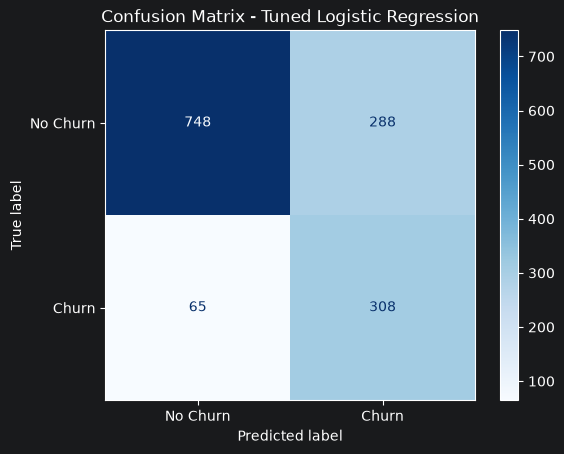

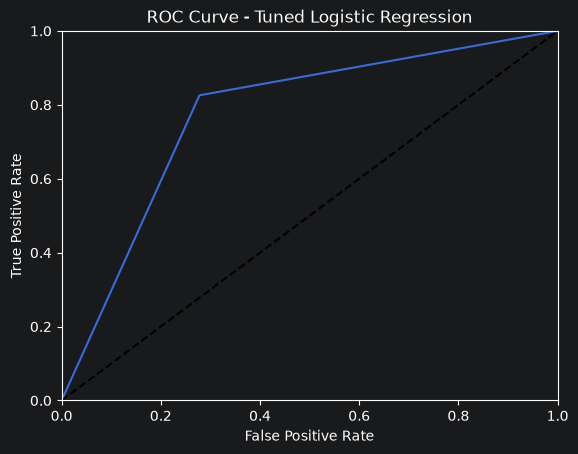

In [42]:
# Fine Tuned Logistic Regression to tackle Class Imbalancing

tunedLog = LogisticRegression(class_weight='balanced', max_iter=1000)
tunedLog.fit(X_train_trans, y_train_num)
tunedLog.fit(X_train_trans, y_train_num)

tunedLog_Predictions = tunedLog.predict(X_test_trans)
tunedLog_prob = tunedLog.predict_proba(X_test_trans)[:,1]

tunedLog_Accuracy = accuracy_score(y_test_num, tunedLog.predict(X_test_trans))
print("Tuned Logistic Regression Accuracy: ", tunedLog_Accuracy)

tunedLog_Precision = precision_score(y_test_num, tunedLog.predict(X_test_trans))
print("Tuned Logistic Regression Precision: ", tunedLog_Precision)

tunedLog_Recall = recall_score(y_test_num, tunedLog.predict(X_test_trans))
print("Tuned Logistic Regression Recall: ", tunedLog_Recall)

tunedLog_F1 = f1_score(y_test_num, tunedLog.predict(X_test_trans))
print("Tuned Logistic Regression F1 Score: ", tunedLog_F1)

tunedLog_Classification_Report = classification_report(y_test_num, tunedLog.predict(X_test_trans))
print("Tuned Logistic Regression Classification Report: \n", tunedLog_Classification_Report)

tunedLog_Confuion = confusion_matrix(y_test_num, tunedLog.predict(X_test_trans))
print("Tuned Logistic Regression Confusion Matrix:\n", tunedLog_Confuion)

ConfusionMatrixDisplay(
    confusion_matrix=tunedLog_Confuion,
    display_labels=['No Churn', 'Churn']
).plot(cmap='Blues')
plt.title('Confusion Matrix - Tuned Logistic Regression')
plt.show()

fpr_tunedLog, tpr_tunedLog, threshold_logReg = roc_curve(y_test_num, tunedLog.predict(X_test_trans))
plt.plot(fpr_tunedLog, tpr_tunedLog)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Logistic Regression')
plt.show()


In [39]:
# Model Comparison DataFrame

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Tuned Logistic Regression"
    ],

    "Accuracy": [
        accuracy_score(y_test_num, logreg_pred),
        accuracy_score(y_test_num, decTree_Predictions),
        accuracy_score(y_test_num, tunedLog_Predictions)
    ],

    "Precision": [
        precision_score(y_test_num, logreg_pred, zero_division=0),
        precision_score(y_test_num, decTree_Predictions, zero_division=0),
        precision_score(y_test_num, tunedLog_Predictions, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test_num, logreg_pred, zero_division=0),
        recall_score(y_test_num, decTree_Predictions, zero_division=0),
        recall_score(y_test_num, tunedLog_Predictions, zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test_num, logreg_pred, zero_division=0),
        f1_score(y_test_num, decTree_Predictions, zero_division=0),
        f1_score(y_test_num, tunedLog_Predictions, zero_division=0)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test_num, logReg_prob),
        roc_auc_score(y_test_num, dectree_prob),
        roc_auc_score(y_test_num, tunedLog_prob)
    ]
})

# Display the comparison table
display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8211,0.6862,0.5979,0.6390,0.8622
1,Decision Tree,0.7999,0.6188,0.6354,0.6270,0.8400
2,Tuned Logistic Regression,0.7495,0.5168,0.8257,0.6357,0.8620


In [47]:
# Extracting the results table

with open('ComparisonTable.txt', 'w') as f:
    f.write("Model Performance Comparison Table\n")
    f.write(model_comparison.to_string())
    f.write("\n")
    f.write("\nClassification Report of Logistic Regression:\n")
    f.write(logReg_classificationReport)
    f.write("\n")
    f.write("\nClassification Report of Decision Tree:\n")
    f.write(decTree_ClassificationReport)
    f.write("\n")
    f.write("\nClassification Report of Tuned Logistic Regression:\n")
    f.write(tunedLog_Classification_Report)
    f.close()